In [1]:
# Librerías para la Actividad 7
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Cargar la base de recursos humanos
data = pd.read_csv("recursos_humanos.csv")

data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [3]:
# Convertir las variables categóricas
data_encoded = pd.get_dummies(
    data,
    columns=["sales", "salary"],
    dtype=int
)

data_encoded.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [4]:
# Separar las variables
X = data_encoded.drop("left", axis=1)
y = data_encoded["left"]

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (14999, 20)
Variable objetivo: (14999,)


In [5]:
# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (11999, 20)
Datos de prueba: (3000, 20)


In [6]:
# Estandarizar los datos
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Primeros 5 registros estandarizados:")
print(X_train_scaled[:5])

Primeros 5 registros estandarizados:
[[ 0.47448128 -0.56264366  0.16256828  0.92157805  0.34250867 -0.41058739
  -0.14497482 -0.29789206 -0.23421602 -0.23183076 -0.23022968 -0.2102582
  -0.24605784 -0.25433247  1.63075055 -0.41914314 -0.47211263 -0.30300287
   1.01876084 -0.86008251]
 [ 0.67561392  1.65763337  0.97398958  0.70131323  1.02861244 -0.41058739
  -0.14497482 -0.29789206 -0.23421602 -0.23183076 -0.23022968 -0.2102582
  -0.24605784 -0.25433247  1.63075055 -0.41914314 -0.47211263 -0.30300287
  -0.98158465  1.16267915]
 [-2.05979004 -0.97164207 -1.46027431  0.92157805  0.34250867 -0.41058739
  -0.14497482 -0.29789206 -0.23421602 -0.23183076 -0.23022968 -0.2102582
  -0.24605784 -0.25433247  1.63075055 -0.41914314 -0.47211263 -0.30300287
  -0.98158465  1.16267915]
 [-0.08869013 -1.20535544 -1.46027431 -1.50133502 -0.34359509 -0.41058739
  -0.14497482 -0.29789206 -0.23421602 -0.23183076 -0.23022968 -0.2102582
  -0.24605784 -0.25433247  1.63075055 -0.41914314 -0.47211263 -0.3030028

In [7]:
# Modelo SVM con Kernel Linear
modelo_linear = SVC(kernel="linear")

modelo_linear.fit(X_train_scaled, y_train)

y_pred_linear = modelo_linear.predict(X_test_scaled)

print("Reporte de clasificación - Kernel Linear")
print(classification_report(y_test, y_pred_linear))

Reporte de clasificación - Kernel Linear
              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2286
           1       0.60      0.27      0.37       714

    accuracy                           0.78      3000
   macro avg       0.70      0.61      0.62      3000
weighted avg       0.75      0.78      0.75      3000



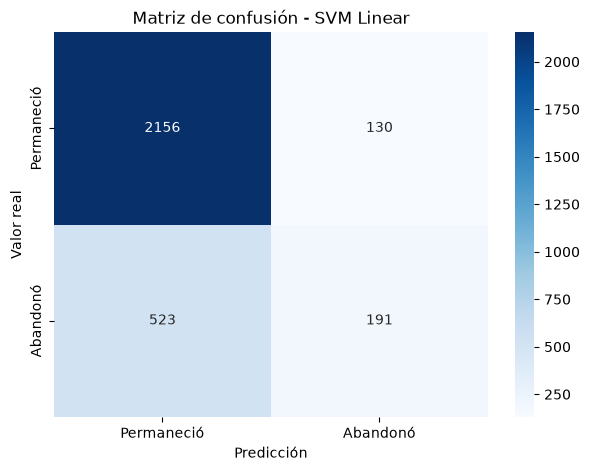

In [8]:
# Matriz de confusión - Kernel Linear
matriz_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permaneció", "Abandonó"],
    yticklabels=["Permaneció", "Abandonó"]
)

plt.title("Matriz de confusión - SVM Linear")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

In [9]:
# Modelo SVM con Kernel Polynomial
modelo_poly = SVC(kernel="poly")

modelo_poly.fit(X_train_scaled, y_train)

y_pred_poly = modelo_poly.predict(X_test_scaled)

print("Reporte de clasificación - Kernel Polynomial")
print(classification_report(y_test, y_pred_poly))

Reporte de clasificación - Kernel Polynomial
              precision    recall  f1-score   support

           0       0.95      0.98      0.96      2286
           1       0.92      0.83      0.88       714

    accuracy                           0.94      3000
   macro avg       0.94      0.91      0.92      3000
weighted avg       0.94      0.94      0.94      3000



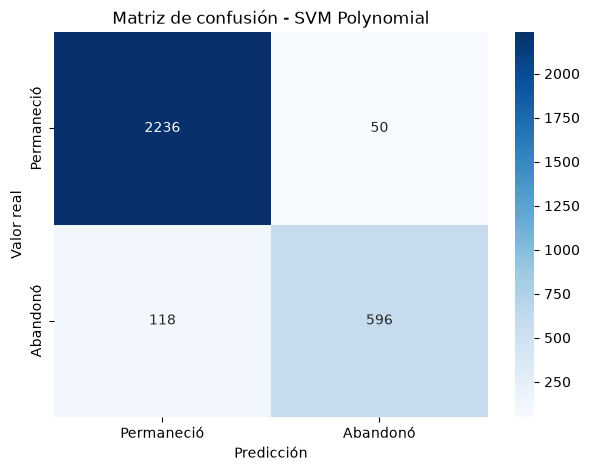

In [10]:
# Matriz de confusión - Kernel Polynomial
matriz_poly = confusion_matrix(y_test, y_pred_poly)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_poly,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permaneció", "Abandonó"],
    yticklabels=["Permaneció", "Abandonó"]
)

plt.title("Matriz de confusión - SVM Polynomial")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

In [11]:
# Modelo SVM con Kernel RBF
modelo_rbf = SVC(kernel="rbf")

modelo_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = modelo_rbf.predict(X_test_scaled)

print("Reporte de clasificación - Kernel RBF")
print(classification_report(y_test, y_pred_rbf))

Reporte de clasificación - Kernel RBF
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      2286
           1       0.90      0.90      0.90       714

    accuracy                           0.95      3000
   macro avg       0.94      0.93      0.93      3000
weighted avg       0.95      0.95      0.95      3000



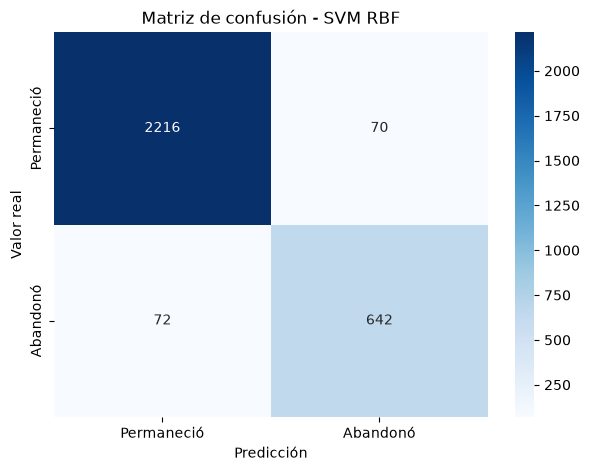

In [12]:
# Matriz de confusión - Kernel RBF
matriz_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_rbf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permaneció", "Abandonó"],
    yticklabels=["Permaneció", "Abandonó"]
)

plt.title("Matriz de confusión - SVM RBF")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

In [13]:
# Modelo SVM con Kernel Sigmoid
modelo_sigmoid = SVC(kernel="sigmoid")

modelo_sigmoid.fit(X_train_scaled, y_train)

y_pred_sigmoid = modelo_sigmoid.predict(X_test_scaled)

print("Reporte de clasificación - Kernel Sigmoid")
print(classification_report(y_test, y_pred_sigmoid))

Reporte de clasificación - Kernel Sigmoid
              precision    recall  f1-score   support

           0       0.77      0.79      0.78      2286
           1       0.25      0.23      0.24       714

    accuracy                           0.65      3000
   macro avg       0.51      0.51      0.51      3000
weighted avg       0.64      0.65      0.65      3000



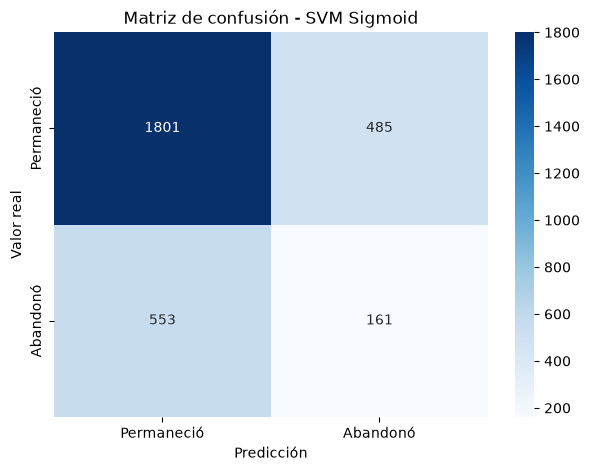

In [14]:
# Matriz de confusión - Kernel Sigmoid
matriz_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_sigmoid,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permaneció", "Abandonó"],
    yticklabels=["Permaneció", "Abandonó"]
)

plt.title("Matriz de confusión - SVM Sigmoid")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

In [15]:
# Comparación de los cuatro kernels
predicciones = {
    "Linear": y_pred_linear,
    "Polynomial": y_pred_poly,
    "RBF": y_pred_rbf,
    "Sigmoid": y_pred_sigmoid
}

resultados = []

for kernel, pred in predicciones.items():
    resultados.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred)
    })

comparacion = pd.DataFrame(resultados)
comparacion.round(4)

,Kernel,Accuracy,Precision,Recall,F1-score
0,Linear,0.7823,0.5950,0.2675,0.3691
1,Polynomial,0.9440,0.9226,0.8347,0.8765
2,RBF,0.9527,0.9017,0.8992,0.9004
3,Sigmoid,0.6540,0.2492,0.2255,0.2368


In [16]:
# Datos del empleado nuevo
empleado = pd.DataFrame([{
    "satisfaction_level": 0.50,
    "last_evaluation": 0.75,
    "number_project": 4,
    "average_montly_hours": 200,
    "time_spend_company": 4,
    "Work_accident": 0,
    "promotion_last_5years": 0,
    "sales": "sales",
    "salary": "medium"
}])

# Convertir las variables categóricas
empleado_encoded = pd.get_dummies(
    empleado,
    columns=["sales", "salary"],
    dtype=int
)

# Acomodar las columnas como en el entrenamiento
empleado_encoded = empleado_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

# Estandarizar y realizar la predicción
empleado_scaled = scaler.transform(empleado_encoded)

prediccion = modelo_rbf.predict(empleado_scaled)

print("Predicción:", prediccion[0])

if prediccion[0] == 1:
    print("El empleado abandonaría la empresa.")
else:
    print("El empleado permanecería en la empresa.")

Predicción: 0
El empleado permanecería en la empresa.
